In [1]:
from correlation_stability import run_stability_analysis
import scanpy as sc
from run_dgcna_correlation import run_dgcna_analysis
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt


In [2]:

adata=sc.read_loom('Integrated_betas.loom') 
adata.obs_names=adata.obs.obs_names
adata.var_names=adata.var.gene_name



C:\Users\Leo\anaconda3\Lib\functools.py:934: ImplicitModificationWarning: Transforming to str index.
  return dispatch(args[0].__class__)(*args, **kw)
C:\Users\Leo\anaconda3\Lib\functools.py:934: ImplicitModificationWarning: Transforming to str index.
  return dispatch(args[0].__class__)(*args, **kw)


In [3]:
#adata=adata[adata.obs.Disease=='T2D'].copy()

import numpy as np

np.random.seed(0)  # optional, for reproducibility
n = adata.n_obs
groups = np.array(['A'] * (n // 2) + ['B'] * (n - n // 2))
np.random.shuffle(groups)

adata.obs['Group'] = groups

In [4]:
sel_genes=pd.read_excel("sel_genes.xlsx")
ndcg_genes=sel_genes.Gene_name.unique()
glyco=sel_genes[sel_genes.Module=='(6) Glycolysis'].Gene_name.values

In [7]:
adata.obs.Disease.value_counts()

Disease
T2D       582
normal    456
Name: count, dtype: int64

In [8]:
n_T2D = 582
n_normal = 456

n_cells = adata.n_obs

assert n_T2D + n_normal == n_cells, (
    f"Expected {n_T2D + n_normal} cells, found {n_cells}"
)

n_random_splits = 30
rng = np.random.default_rng(42)

summary = []

for it in range(n_random_splits):

    # Randomly shuffle cell indices
    shuffled_cells = rng.permutation(n_cells)

    # Preserve the original group sizes exactly
    group_labels = np.empty(n_cells, dtype=object)
    group_labels[shuffled_cells[:n_T2D]] = 'B'
    group_labels[shuffled_cells[n_T2D:]] = 'A'

    adata.obs['Group'] = group_labels

    assert (adata.obs['Group'] == 'B').sum() == n_T2D
    assert (adata.obs['Group'] == 'A').sum() == n_normal

    # Run dGCNA
    results = run_dgcna_analysis(
        adata,
        genes=ndcg_genes,
        disease_col='Group',
        t2d_value='B',
        ctrl_value='A',
        n_bootstrap=512,
        threshold=0.975
    )

    corr = results['filtered_net']

    # Upper triangle only
    upper = np.triu(corr.values, k=1)
    sig_delta = np.abs(upper[upper != 0])

    n_genes = corr.shape[0]
    n_total = n_genes * (n_genes - 1) // 2

    summary.append({
        'iteration': it + 1,
        'n_T2D': n_T2D,
        'n_normal': n_normal,
        'n_sig': len(sig_delta),
        'pct_sig': 100 * len(sig_delta) / n_total,
        'median_abs_delta_r': (
            np.median(sig_delta) if len(sig_delta) else np.nan
        )
    })

summary_df = pd.DataFrame(summary)

summary_df.to_csv(
    "dGCNA_random_cell_splits.csv",
    index=False
)

print(f"Completed {len(summary_df)} random cell splits.")

Using 664 / 671 specified genes

=== Step 1: Computing LMM residuals (per condition) ===
Cells: 582, donors: 17, genes: 664
Cells: 456, donors: 17, genes: 664

=== Step 2: Building differential network ===
T2D cells: 582, Control cells: 456

=== Step 3: Bootstrap filtering ===


Random donor groups (with replacement): 100%|████████████████████████████████████████| 512/512 [01:53<00:00,  4.51it/s]


Significant edges: 31330 / 220116 (14.2%)
Using 664 / 671 specified genes

=== Step 1: Computing LMM residuals (per condition) ===
Cells: 582, donors: 17, genes: 664
Cells: 456, donors: 17, genes: 664

=== Step 2: Building differential network ===
T2D cells: 582, Control cells: 456

=== Step 3: Bootstrap filtering ===


Random donor groups (with replacement): 100%|████████████████████████████████████████| 512/512 [02:10<00:00,  3.91it/s]


Significant edges: 33684 / 220116 (15.3%)
Using 664 / 671 specified genes

=== Step 1: Computing LMM residuals (per condition) ===
Cells: 582, donors: 17, genes: 664
Cells: 456, donors: 17, genes: 664

=== Step 2: Building differential network ===
T2D cells: 582, Control cells: 456

=== Step 3: Bootstrap filtering ===


...

Significant edges: 32148 / 220116 (14.6%)
Using 664 / 671 specified genes

=== Step 1: Computing LMM residuals (per condition) ===
Cells: 582, donors: 17, genes: 664
Cells: 456, donors: 17, genes: 664

=== Step 2: Building differential network ===
T2D cells: 582, Control cells: 456

=== Step 3: Bootstrap filtering ===


Random donor groups (with replacement): 100%|████████████████████████████████████████| 512/512 [02:12<00:00,  3.88it/s]


Significant edges: 35569 / 220116 (16.2%)
Using 664 / 671 specified genes

=== Step 1: Computing LMM residuals (per condition) ===
Cells: 582, donors: 17, genes: 664
Cells: 456, donors: 17, genes: 664

=== Step 2: Building differential network ===
T2D cells: 582, Control cells: 456

=== Step 3: Bootstrap filtering ===


Random donor groups (with replacement): 100%|████████████████████████████████████████| 512/512 [02:06<00:00,  4.05it/s]

Significant edges: 33447 / 220116 (15.2%)
Completed 30 random cell splits.


In [9]:

# Summary
print("\nSummary:")
print(f"Number of unique splits: {len(summary_df)}")
print(
    f"Significant edges — median: "
    f"{summary_df['n_sig'].median():.0f}"
)
print(
    f"Significant edges — range: "
    f"{summary_df['n_sig'].min():.0f}–"
    f"{summary_df['n_sig'].max():.0f}"
)
print(
    f"Percentage significant — median: "
    f"{summary_df['pct_sig'].median():.1f}%"
)
print(
    f"Percentage significant — range: "
    f"{summary_df['pct_sig'].min():.1f}–"
    f"{summary_df['pct_sig'].max():.1f}%"
)
print(
    f"Median |Δr| across splits: "
    f"{summary_df['median_abs_delta_r'].median():.3f}"
)



Summary:
Number of unique splits: 30
Significant edges — median: 31680
Significant edges — range: 28785–38995
Percentage significant — median: 14.4%
Percentage significant — range: 13.1–17.7%
Median |Δr| across splits: 0.124


C:\Users\Leo\AppData\Local\Temp\ipykernel_23984\234781647.py:11: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend()


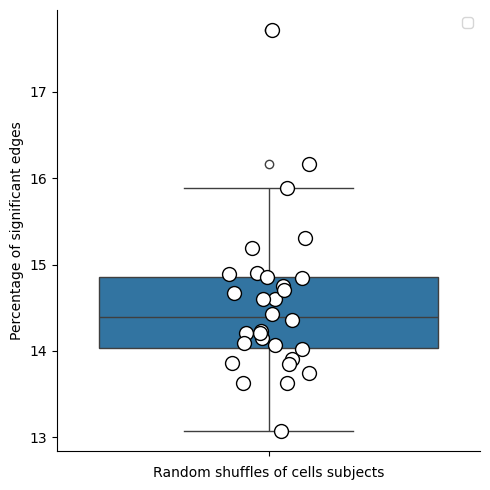

In [11]:
# Distribution of % of significant edges on random shuffles of control donors
fig, ax = plt.subplots(figsize=(5, 5))

sns.boxplot(summary_df, y='pct_sig')
sns.stripplot(summary_df, y='pct_sig',  linewidth=1, color='w', s=10, edgecolor='k')

ax.set_xlabel(f'Random shuffles of cells subjects')
ax.set_ylabel(f'Percentage of significant edges')
#ax.set_title(f'CTRL Sample ({largest_ctrl_donor}, n={largest_ctrl_n})\nr = {r_resid_ctrl:.3f}')
ax.spines[['top', 'right']].set_visible(False)
ax.legend()
sns.despine()
plt.tight_layout()
#plt.savefig('Figure3/pct_significant_T2D.png')
#plt.savefig('Figure3/pct_significant_T2D.svg')